# Coronal-hole latitude grid, B0 and darkness (not built)

**The question:** does splitting the central-meridian coronal-hole strip by latitude, correcting
for Earth's B0 tilt, or weighting holes by darkness improve the linear model?

**Why it might:** Collin et al. (2025) find that central, low-latitude cells of a coronal-hole grid
matter most and that Earth's heliographic latitude B0 (±7.25° over the year) matters; darker holes
give faster streams (Obridko et al. 2009). Our strip ignores B0 and covers |lat| ≤ 60°.

**The metrics** (`feature_engineering.coronal_holes.grid_metrics`, recomputed from the 13,950
usable cached AIA 193 Å images by `python -m training.coronal_grid images`), all within
|longitude| ≤ 10° with B0-corrected latitudes:

| name | region |
|---|---|
| `ch_cm_b0` | \|lat\| ≤ 60° (the shipped strip, B0-corrected) |
| `ch_cm_low` | \|lat\| ≤ 30° |
| `ch_cm_earth` | \|lat − B0\| ≤ 15° |
| `ch_cm_toward` / `ch_cm_away` | the hemisphere tilted towards / away from Earth, 10° < \|lat\| ≤ 60° |
| `ch_cm_depth` | \|lat\| ≤ 60°, each hole pixel weighted by how far below the threshold it is |

**Setup** (`python -m training.coronal_grid folds`): every metric is lead-aligned at D = 72 h, like
the winner of `training.lead_aligned_ch`, whose linear model ("at 72", score 0.4257) is the
reference. Variants replace the strip with a metric, or add the metric to it; "+ b0" adds B0 at t0.
Six yearly walk-forward folds (2019-10 → 2025-10); score: per-run mean TIMSE / persistence,
geometric mean over folds. The eval year is not used.

1. Fold scores
2. By fold: the solar-cycle pattern
3. The metrics over the cycle
4. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import coronal_grid as cg

df = pd.read_csv(cg.EXPERIMENTS / "coronal_grid.csv").set_index("fold")
cols = [c for c in df.columns if c.startswith("linear")]


def geo(c):
    return float(np.exp(np.log(df[c]).mean()))

## 1. Fold scores (lower is better)

In [2]:
summary = pd.DataFrame({c: {"score": geo(c), "vs ref": geo(c) / geo("linear ref") - 1,
                            "folds won": int((df[c] < df["linear ref"]).sum())}
                        for c in cols}).T.sort_values("score")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)

,score,vs ref,folds won
linear + ch_cm_earth,0.4246,-0.0027,3.0000
linear + ch_cm_away,0.4246,-0.0026,3.0000
linear + ch_cm_low,0.4251,-0.0013,4.0000
linear ref,0.4257,0.0000,0.0000
linear + ch_cm_toward,0.4259,0.0005,2.0000
linear + ch_cm_depth,0.4261,0.0009,2.0000
linear + toward/away,0.4262,0.0011,2.0000
linear + b0,0.4275,0.0043,3.0000
linear ch_cm_depth,0.4280,0.0054,2.0000
linear ch_cm_b0,0.4281,0.0057,4.0000


## 2. By fold: the solar-cycle pattern

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear ch_cm_b0,2.9,2.8,-1.2,-0.8,-0.0,-0.2
linear ch_cm_low,21.4,11.1,-1.6,-5.7,-2.0,-5.9
linear + ch_cm_low,7.2,2.2,-0.6,-2.8,-2.5,-3.8
linear ch_cm_earth,23.0,13.1,0.9,-8.3,1.6,-2.4
linear + ch_cm_earth,6.8,1.9,0.0,-5.0,-1.5,-3.4
linear ch_cm_toward,0.8,2.5,1.9,5.3,5.3,7.7
linear + ch_cm_toward,-2.2,-1.6,1.1,1.6,0.3,1.2
linear ch_cm_away,22.3,14.7,1.2,5.1,8.0,5.1
linear + ch_cm_away,-1.2,-1.2,0.8,-1.3,0.9,0.5
linear ch_cm_depth,-2.0,1.6,0.6,0.9,-1.1,3.4


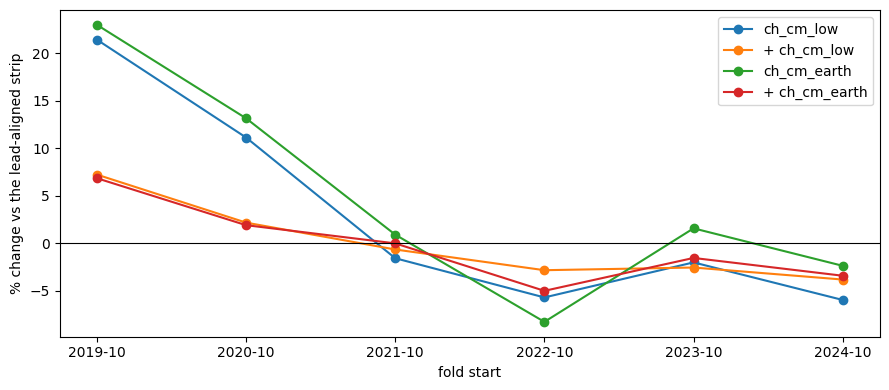

In [3]:
change = pd.DataFrame({c: 100 * (df[c] / df["linear ref"] - 1) for c in cols if c != "linear ref"})
display(change.T.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
for c in ("linear ch_cm_low", "linear + ch_cm_low", "linear ch_cm_earth", "linear + ch_cm_earth"):
    ax.plot(change.index, change[c], "o-", label=c.removeprefix("linear "))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("% change vs the lead-aligned strip")
ax.set_xlabel("fold start")
ax.legend()
plt.tight_layout()

## 3. The metrics over the cycle (monthly means)

,ch_cm_b0,ch_cm_low,ch_cm_earth,ch_cm_toward,ch_cm_away,ch_cm_depth,low / all
cutoff,,,,,,,
2016,0.0943,0.0764,0.0661,0.1081,0.0948,0.0562,0.8101
2017,0.0590,0.0476,0.0490,0.0905,0.0364,0.0347,0.8075
2018,0.0652,0.0579,0.0583,0.0501,0.0787,0.0361,0.8878
2019,0.0574,0.0582,0.0656,0.0636,0.0500,0.0283,1.0142
2020,0.0465,0.0392,0.0522,0.0564,0.0314,0.0202,0.8427
2021,0.0435,0.0387,0.0418,0.0436,0.0407,0.0215,0.8899
2022,0.0303,0.0345,0.0412,0.0264,0.0265,0.0141,1.1389
2023,0.0234,0.0213,0.0261,0.0296,0.0149,0.0105,0.9118
2024,0.0228,0.0162,0.0166,0.0339,0.0169,0.0089,0.7074


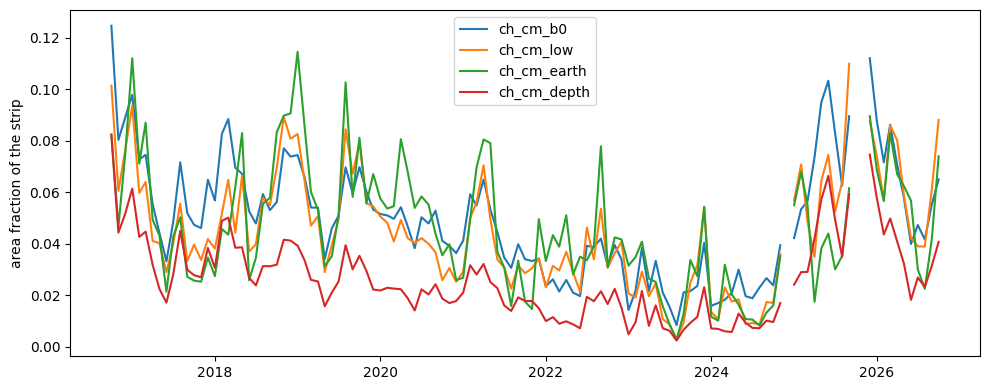

In [4]:
grid = cg.load_grid()
monthly = grid[list(cg.NAMES)].resample("MS").mean()
fig, ax = plt.subplots(figsize=(10, 4))
for c in ("ch_cm_b0", "ch_cm_low", "ch_cm_earth", "ch_cm_depth"):
    ax.plot(monthly.index, monthly[c], label=c)
ax.set_ylabel("area fraction of the strip")
ax.legend()
plt.tight_layout()
yearly = grid[list(cg.NAMES)].groupby(grid.index.year).mean()
yearly["low / all"] = yearly["ch_cm_low"] / yearly["ch_cm_b0"]
display(yearly.round(4))

## 4. Findings

- **Not built: nothing passes the bar.** The best additions are worth 0.1–0.3% (the Earth-facing band, the away hemisphere, the low-latitude strip, each added to the lead-aligned strip), winning 3–4 of 6 folds. Every replacement is worse overall.
- **The low-latitude strip splits by the solar cycle.** Replacing the strip with |lat| ≤ 30° gains 1.6–5.9% in the 2021–2024 folds (rising phase and maximum) and loses 21% and 11% in the 2019 and 2020 folds (minimum). The Earth-facing band behaves the same way. The single 2024 pilot fold (−5.9%) was the most favourable one.
- **The share of hole area at low latitude doesn't explain it:** it is 0.7–1.1 of the full strip in every year, with no cycle trend. The 30–60° parts of the holes carry information the low band drops, and the evidence here says that information matters most around minimum, when polar holes and their extensions feed the fast wind. A cycle-dependent weighting of the bands is a possible follow-up, but six folds can't support choosing it.
- **B0 adds nothing:** correcting the latitudes for B0 costs 0.6%, and B0 at t0 as an input 0.4%. At |lon| ≤ 10° and |lat| ≤ 60° the correction moves little area, and a seasonal term has nothing to explain at this level.
- **Hemispheres and darkness hurt as replacements** (+0.5% to +9%) and are neutral as additions; the darkness weighting mostly rescales the area (its yearly means follow the strip's).
- **Decision:** not built. The lead-aligned full strip stays the coronal-hole input. The metrics code (`coronal_holes.grid_metrics`, `b0_angle`) and `training.coronal_grid` are kept as the record (`docs/coronal_grid.md`).